In [3]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data_folder = Path("../data/raw")
csv_files = list(data_folder.glob("*.csv"))

print("CSV files found:", len(csv_files))

for file in csv_files:
    print(file.name)

CSV files found: 1
PS_20174392719_1491204439457_log.csv


In [5]:
# Load the PaySim dataset
csv_path = csv_files[0]

df = pd.read_csv(csv_path)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.head()

Dataset loaded successfully!
Number of rows: 6362620
Number of columns: 11


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [6]:
# Inspect data types and dataset structure
df.info()

print("\nMissing values per column:")
print(df.isna().sum())

print("\nFraud label counts:")
print(df["isFraud"].value_counts())

print("\nFraud label percentages:")
print(
    (df["isFraud"].value_counts(normalize=True) * 100).round(4)
)

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 534.0 MB

Missing values per column:
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

Fraud label counts:
isFraud
0    6354407
1       8213
Name: count, dtype: int64

Fraud label percentages:
isFraud
0    99.8709
1     0.1291
Name: proportion, dtype: float64


In [7]:
print("Missing values:")
print(df.isna().sum().to_string())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nFraud counts:")
print(df["isFraud"].value_counts().sort_index().to_string())

print("\nTransaction types:")
print(df["type"].value_counts().to_string())

Missing values:
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0

Duplicate rows: 0

Fraud counts:
isFraud
0    6354407
1       8213

Transaction types:
type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432


In [8]:
fraud_by_type = (
    df.groupby("type")["isFraud"]
    .agg(total_transactions="count", fraud_cases="sum")
)

fraud_by_type["legitimate_cases"] = (
    fraud_by_type["total_transactions"] - fraud_by_type["fraud_cases"]
)

fraud_by_type["fraud_rate_pct"] = (
    fraud_by_type["fraud_cases"]
    / fraud_by_type["total_transactions"]
    * 100
)

display(fraud_by_type.sort_values("fraud_rate_pct", ascending=False).round(4))

,total_transactions,fraud_cases,legitimate_cases,fraud_rate_pct
type,,,,
TRANSFER,532909,4097,528812,0.7688
CASH_OUT,2237500,4116,2233384,0.1840
CASH_IN,1399284,0,1399284,0.0000
DEBIT,41432,0,41432,0.0000
PAYMENT,2151495,0,2151495,0.0000


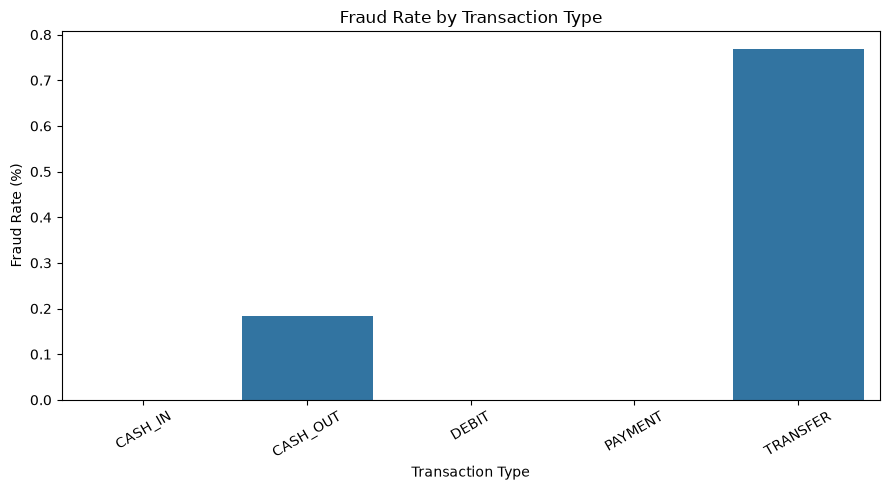

In [9]:
plot_data = fraud_by_type.reset_index()

plt.figure(figsize=(9, 5))

sns.barplot(
    data=plot_data,
    x="type",
    y="fraud_rate_pct"
)

plt.title("Fraud Rate by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [10]:
print("LEGITIMATE TRANSACTION AMOUNTS")
print(
    df.loc[df["isFraud"] == 0, "amount"]
    .describe(percentiles=[0.5, 0.9, 0.99])
    .round(2)
)

print("\nFRAUD TRANSACTION AMOUNTS")
print(
    df.loc[df["isFraud"] == 1, "amount"]
    .describe(percentiles=[0.5, 0.9, 0.99])
    .round(2)
)

LEGITIMATE TRANSACTION AMOUNTS
count     6354407.00
mean       178197.04
std        596236.98
min             0.01
50%         74684.72
90%        364373.44
99%       1586064.17
max      92445516.64
Name: amount, dtype: float64

FRAUD TRANSACTION AMOUNTS
count        8213.00
mean      1467967.30
std       2404252.95
min             0.00
50%        441423.44
90%       4521723.51
99%      10000000.00
max      10000000.00
Name: amount, dtype: float64


In [11]:
print("Fraud transactions by type:")
print(
    df[df["isFraud"] == 1]["type"]
    .value_counts()
)

print("\nFraud transactions: sample balance details")
display(
    df.loc[
        df["isFraud"] == 1,
        [
            "type",
            "amount",
            "oldbalanceOrg",
            "newbalanceOrig",
            "oldbalanceDest",
            "newbalanceDest"
        ]
    ].head(10)
)

Fraud transactions by type:
type
CASH_OUT    4116
TRANSFER    4097
Name: count, dtype: int64

Fraud transactions: sample balance details


,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest
2,TRANSFER,181.00,181.00,0.0,0.0,0.00
3,CASH_OUT,181.00,181.00,0.0,21182.0,0.00
251,TRANSFER,2806.00,2806.00,0.0,0.0,0.00
252,CASH_OUT,2806.00,2806.00,0.0,26202.0,0.00
680,TRANSFER,20128.00,20128.00,0.0,0.0,0.00
681,CASH_OUT,20128.00,20128.00,0.0,6268.0,12145.85
724,CASH_OUT,416001.33,0.00,0.0,102.0,9291619.62
969,TRANSFER,1277212.77,1277212.77,0.0,0.0,0.00
970,CASH_OUT,1277212.77,1277212.77,0.0,0.0,2444985.19
1115,TRANSFER,35063.63,35063.63,0.0,0.0,0.00


In [12]:
df["origin_balance_change"] = (
    df["oldbalanceOrg"] - df["newbalanceOrig"]
)

df["origin_change_minus_amount"] = (
    df["origin_balance_change"] - df["amount"]
)

print("Median balance-change difference:")
print(
    df.groupby("isFraud")["origin_change_minus_amount"]
    .median()
)

print("\nPercentage where sender balance change equals amount:")
print(
    df.assign(
        balance_matches_amount=np.isclose(
            df["origin_balance_change"],
            df["amount"],
            rtol=1e-5,
            atol=0.01
        )
    )
    .groupby("isFraud")["balance_matches_amount"]
    .mean()
    .mul(100)
    .round(2)
)

Median balance-change difference:
isFraud
0   -69049.31
1        0.00
Name: origin_change_minus_amount, dtype: float64

Percentage where sender balance change equals amount:
isFraud
0    21.30
1    99.45
Name: balance_matches_amount, dtype: float64


In [13]:
df["origin_balance_sufficient"] = (
    df["oldbalanceOrg"] >= df["amount"]
)

print("Percentage with sufficient sender balance:")
print(
    df.groupby("isFraud")["origin_balance_sufficient"]
    .mean()
    .mul(100)
    .round(2)
)

Percentage with sufficient sender balance:
isFraud
0    35.81
1    99.65
Name: origin_balance_sufficient, dtype: float64


In [14]:
print(
    df.groupby(["type", "isFraud"])["origin_balance_sufficient"]
    .agg(["mean", "count"])
    .assign(
        percentage=lambda x: (x["mean"] * 100).round(2)
    )
)

                      mean    count  percentage
type     isFraud                               
CASH_IN  0        0.658728  1399284       65.87
CASH_OUT 0        0.112961  2233384       11.30
         1        0.994169     4116       99.42
DEBIT    0        0.715534    41432       71.55
PAYMENT  0        0.488205  2151495       48.82
TRANSFER 0        0.040288   528812        4.03
         1        0.998780     4097       99.88
